# Cell 1 — Environment check

In [1]:
import os, sys, json, time, random, shutil
from pathlib import Path

import numpy as np
import pandas as pd

import torch
print("Python:", sys.version)
print("Torch:", torch.__version__)
print("CUDA:", torch.cuda.is_available(), "| Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
Torch: 2.9.0+cu126
CUDA: True | Device: Tesla P100-PCIE-16GB


# Cell 2 — Dependencies

In [2]:
import os, sys, subprocess, importlib

os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"

def pip_install(pkgs, no_deps=True):
    cmd = [sys.executable, "-m", "pip", "install", "-q", "--no-cache-dir", "-U", "--force-reinstall"]
    if no_deps:
        cmd += ["--no-deps"]
    cmd += pkgs
    subprocess.check_call(cmd)

def pip_uninstall(pkgs):
    subprocess.call([sys.executable, "-m", "pip", "uninstall", "-y"] + pkgs)

def purge_modules(prefixes):
    for k in list(sys.modules.keys()):
        if any(k == p or k.startswith(p + ".") for p in prefixes):
            del sys.modules[k]

def ensure_albumentations_stack():

    try:
        import albucore, albumentations as A
        from albucore.utils import preserve_channel_dim
        from albumentations.pytorch import ToTensorV2
        return True
    except Exception:
        pass

    pip_uninstall(["albumentations", "albucore"])
    purge_modules(["albumentations", "albucore"])


    for albucore_ver in ["0.0.15", "0.0.16"]:
        pip_install([f"albucore=={albucore_ver}", "albumentations==1.4.14"], no_deps=True)
        purge_modules(["albumentations", "albucore"])
        try:
            import albucore, albumentations as A
            from albucore.utils import preserve_channel_dim
            from albumentations.pytorch import ToTensorV2
            return True
        except Exception as e:
            last_err = e

    raise ImportError(f"Albumentations stack still broken after reinstall attempts: {repr(last_err)}")


import cv2
from tqdm import tqdm


ensure_albumentations_stack()


try:
    import segmentation_models_pytorch as smp
except Exception:
    pip_install(["segmentation-models-pytorch==0.3.3", "timm==0.9.12", "pretrainedmodels==0.7.4", "efficientnet-pytorch==0.7.1"], no_deps=True)
    purge_modules(["segmentation_models_pytorch", "timm", "pretrainedmodels", "efficientnet_pytorch"])
    import segmentation_models_pytorch as smp

# Final verification (must succeed)
import albumentations as A
import albucore
from albucore.utils import preserve_channel_dim
from albumentations.pytorch import ToTensorV2

print("cv2:", cv2.__version__)
print("albumentations:", A.__version__)
print("albucore:", albucore.__version__)
print("smp:", smp.__version__)
print("preserve_channel_dim: OK")
print("Dependencies OK")

Found existing installation: albumentations 2.0.8
Uninstalling albumentations-2.0.8:
  Successfully uninstalled albumentations-2.0.8
Found existing installation: albucore 0.0.24
Uninstalling albucore-0.0.24:
  Successfully uninstalled albucore-0.0.24
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 11.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 13.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.7/106.7 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 56.8 MB/s eta 0:00:00
cv2: 4.12.0
albumentations: 1.4.14
albucore: 0.0.15
smp: 0.3.3
preserve_channel_dim: OK
Dependencies OK


# Cell 3 — Protocol v1 config

In [3]:
SEED = 7
IMG_SIZE = 448
BATCH_SIZE = 12
LR = 2e-4
WEIGHT_DECAY = 1e-4

EPOCHS = 40
EARLY_STOPPING_PATIENCE = 8


W_BCE = 1.0
W_DICE = 1.0
W_EDGE = 0.5


FAST_MODE = True
REPRO_MODE = False  
NUM_WORKERS = 2
PREFETCH_FACTOR = 2

MODEL_NAME = "unetplusplus_efficientnetb3"
RUN_NAME = "seg_unetpp_proto1_448"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = (DEVICE.type == "cuda")

OUT = Path("/kaggle/working/output")
RUN_DIR = OUT / "runs" / RUN_NAME
FIG_DIR = RUN_DIR / "figures"
CKPT_DIR = RUN_DIR / "checkpoints"
SAVED_MODELS_DIR = OUT / "SAVED_MODELS" / MODEL_NAME
BUNDLES_DIR = OUT / "BUNDLES"

for d in [OUT, RUN_DIR, FIG_DIR, CKPT_DIR, SAVED_MODELS_DIR, BUNDLES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

BEST_PATH = CKPT_DIR / f"{MODEL_NAME}_best.pt"
LAST_PATH = CKPT_DIR / f"{MODEL_NAME}_last.pt"

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

if DEVICE.type == "cuda":
    if REPRO_MODE:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    else:
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True

print("DEVICE:", DEVICE, "| AMP:", AMP)
print("RUN_DIR:", RUN_DIR)

DEVICE: cuda | AMP: True
RUN_DIR: /kaggle/working/output/runs/seg_unetpp_proto1_448


# Cell 4 — Auto-detect Kaggle input paths

In [4]:
KAGGLE_INPUT = Path("/kaggle/input")

def find_dir_named(dir_name: str) -> Path:
    hits = sorted([p for p in KAGGLE_INPUT.rglob(dir_name) if p.is_dir()])
    if not hits:
        raise FileNotFoundError(f"Could not find directory named: {dir_name}")
    return hits[0]

def find_first_file(name: str) -> Path:
    hits = sorted([p for p in KAGGLE_INPUT.rglob(name) if p.is_file()])
    if not hits:
        raise FileNotFoundError(f"Could not find file: {name}")
    return hits[0]

seg_root = find_dir_named("crack_segmentation_dataset")
images_dir = seg_root / "images"
masks_dir  = seg_root / "masks"
assert images_dir.exists() and masks_dir.exists(), f"Missing images/masks under {seg_root}"

train_split_csv = find_first_file("train_split.csv")
val_split_csv   = find_first_file("val_split.csv")

print("Seg root:", seg_root)
print("train_split.csv:", train_split_csv)
print("val_split.csv:", val_split_csv)

Seg root: /kaggle/input/datasets/lakshaymiddha/crack-segmentation-dataset/crack_segmentation_dataset
train_split.csv: /kaggle/input/datasets/arman00p/phase-3-csv/train_split.csv
val_split.csv: /kaggle/input/datasets/arman00p/phase-3-csv/val_split.csv


# Cell 5 — Load split CSVs and resolve image/mask paths robustly

In [5]:
def build_stem_index(folder: Path):
    idx = {}
    for p in folder.glob("*"):
        if p.is_file():
            idx[p.stem] = p
    return idx

img_index = build_stem_index(images_dir)
msk_index = build_stem_index(masks_dir)

def resolve_paths(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    if "image_path" not in df.columns and "image" in df.columns:
        df["image_path"] = df["image"]
    if "mask_path" not in df.columns and "mask" in df.columns:
        df["mask_path"] = df["mask"]

    if "stem" not in df.columns:
        if "image_path" in df.columns:
            df["stem"] = df["image_path"].apply(lambda x: Path(str(x)).stem)
        else:
            raise ValueError("Split CSV must contain 'stem' or 'image_path'.")

    if "image_path" not in df.columns:
        df["image_path"] = np.nan
    if "mask_path" not in df.columns:
        df["mask_path"] = np.nan

    def _resolve_img(stem, ip):
        ip = Path(str(ip)) if pd.notna(ip) else None
        if ip is not None and str(ip).startswith("/kaggle") and ip.exists():
            return str(ip)
        if stem in img_index:
            return str(img_index[stem])
        raise FileNotFoundError(f"Could not resolve image for stem={stem}")

    def _resolve_msk(stem, mp):
        mp = Path(str(mp)) if pd.notna(mp) else None
        if mp is not None and str(mp).startswith("/kaggle") and mp.exists():
            return str(mp)
        if stem in msk_index:
            return str(msk_index[stem])
        raise FileNotFoundError(f"Could not resolve mask for stem={stem}")

    df["image_path"] = [_resolve_img(st, ip) for st, ip in zip(df["stem"], df["image_path"])]
    df["mask_path"]  = [_resolve_msk(st, mp) for st, mp in zip(df["stem"], df["mask_path"])]

    return df[["stem", "image_path", "mask_path"]]

df_train = resolve_paths(pd.read_csv(train_split_csv))
df_val   = resolve_paths(pd.read_csv(val_split_csv))

print("Train:", df_train.shape, "| Val:", df_val.shape)
df_train.head(2)

Train: (9603, 3) | Val: (1695, 3)


,stem,image_path,mask_path
0,forest_083,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...
1,CRACK500_20160328_151728_1281_361,/kaggle/input/datasets/lakshaymiddha/crack-seg...,/kaggle/input/datasets/lakshaymiddha/crack-seg...


# Cell 6 — Augmentations + Dataset + DataLoaders

In [6]:
import cv2
cv2.setNumThreads(0)

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

train_aug = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE, interpolation=cv2.INTER_AREA),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=20, p=0.5, border_mode=cv2.BORDER_REFLECT_101),
    A.RandomBrightnessContrast(p=0.5),
    A.GaussNoise(p=0.2),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(transpose_mask=True),
])

val_aug = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE, interpolation=cv2.INTER_AREA),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(transpose_mask=True),
])

class CrackSegDataset(torch.utils.data.Dataset):
    def __init__(self, df, aug):
        self.df = df.reset_index(drop=True)
        self.aug = aug
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        r = self.df.iloc[idx]
        ip, mp = r["image_path"], r["mask_path"]

        img = cv2.imread(ip, cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(f"cv2 failed to read image: {ip}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if m is None:
            raise FileNotFoundError(f"cv2 failed to read mask: {mp}")
        m = (m > 127).astype(np.uint8)

        out = self.aug(image=img, mask=m)
        x = out["image"]
        y = out["mask"]
        if y.ndim == 2:
            y = y.unsqueeze(0)
        return x, y.float()

train_ds = CrackSegDataset(df_train, train_aug)
val_ds   = CrackSegDataset(df_val, val_aug)

def make_loader(ds, batch_size, shuffle, num_workers):
    kwargs = dict(batch_size=batch_size, shuffle=shuffle, num_workers=num_workers,
                  pin_memory=True, drop_last=shuffle)
    if num_workers > 0:
        kwargs["persistent_workers"] = True
        kwargs["prefetch_factor"] = PREFETCH_FACTOR
    return torch.utils.data.DataLoader(ds, **kwargs)

try:
    train_loader = make_loader(train_ds, BATCH_SIZE, True, NUM_WORKERS)
    val_loader   = make_loader(val_ds,   BATCH_SIZE, False, NUM_WORKERS)
    _ = next(iter(train_loader))
    print("DataLoader OK with num_workers =", NUM_WORKERS)
except Exception as e:
    print("Multiprocessing DataLoader failed, fallback to num_workers=0:", repr(e))
    train_loader = make_loader(train_ds, BATCH_SIZE, True, 0)
    val_loader   = make_loader(val_ds,   BATCH_SIZE, False, 0)

xb, yb = next(iter(train_loader))
print("Batch x:", xb.shape, xb.dtype, "| y:", yb.shape, yb.dtype)

DataLoader OK with num_workers = 2
Batch x: torch.Size([12, 3, 448, 448]) torch.float32 | y: torch.Size([12, 1, 448, 448]) torch.float32


# Cell 7 — Model-3 (UNet++) + losses + metrics + optimizer + scheduler + AMP scaler

In [7]:
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau

model = smp.UnetPlusPlus(
    encoder_name="efficientnet-b3",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(DEVICE)

bce = nn.BCEWithLogitsLoss()

def soft_dice_loss(logits, targets, eps=1e-6):
    probs = torch.sigmoid(logits)
    probs = probs.view(probs.size(0), -1)
    targets = targets.view(targets.size(0), -1)
    inter = (probs * targets).sum(dim=1)
    den = probs.sum(dim=1) + targets.sum(dim=1)
    dice = (2 * inter + eps) / (den + eps)
    return 1.0 - dice.mean()

_sobel_x = torch.tensor([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=torch.float32).view(1,1,3,3)
_sobel_y = torch.tensor([[-1,-2,-1],[0,0,0],[1,2,1]], dtype=torch.float32).view(1,1,3,3)

def edge_loss(logits, targets):
    probs = torch.sigmoid(logits)
    sx = _sobel_x.to(probs.device)
    sy = _sobel_y.to(probs.device)
    px = F.conv2d(probs, sx, padding=1)
    py = F.conv2d(probs, sy, padding=1)
    tx = F.conv2d(targets, sx, padding=1)
    ty = F.conv2d(targets, sy, padding=1)
    pg = torch.sqrt(px*px + py*py + 1e-6)
    tg = torch.sqrt(tx*tx + ty*ty + 1e-6)
    return F.l1_loss(pg, tg)

def total_loss(logits, targets):
    return (W_BCE * bce(logits, targets) +
            W_DICE * soft_dice_loss(logits, targets) +
            W_EDGE * edge_loss(logits, targets))

@torch.no_grad()
def iou_from_logits(logits, targets, thr=0.5, eps=1e-6):
    probs = torch.sigmoid(logits)
    pred = (probs > thr).float()
    inter = (pred * targets).sum(dim=(1,2,3))
    union = (pred + targets - pred*targets).sum(dim=(1,2,3))
    return ((inter + eps) / (union + eps)).mean().item()

@torch.no_grad()
def pixel_acc_from_logits(logits, targets, thr=0.5):
    probs = torch.sigmoid(logits)
    pred = (probs > thr).float()
    return (pred == targets).float().mean().item()

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

scheduler = ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, threshold=1e-4, min_lr=1e-6
)

scaler = torch.amp.GradScaler(enabled=AMP)

print("Params (M):", sum(p.numel() for p in model.parameters())/1e6)

Downloading: "https://github.com/lukemelas/EfficientNet-PyTorch/releases/download/1.0/efficientnet-b3-5fb5a3c3.pth" to /root/.cache/torch/hub/checkpoints/efficientnet-b3-5fb5a3c3.pth


100%|██████████| 47.1M/47.1M [00:00<00:00, 90.7MB/s]


Params (M): 13.624793


# Cell 8 — Training + checkpointing + final zip bundle

In [8]:
import time
from pathlib import Path

# TF32 control (speed, safe for CNN training; keeps logs clean)
if DEVICE.type == "cuda" and FAST_MODE and not REPRO_MODE:
    torch.backends.cuda.matmul.fp32_precision = "tf32"
    torch.backends.cudnn.conv.fp32_precision = "tf32"
else:
    torch.backends.cuda.matmul.fp32_precision = "ieee"
    torch.backends.cudnn.conv.fp32_precision = "ieee"

# channels_last speed path for convnets
if DEVICE.type == "cuda" and FAST_MODE:
    model = model.to(memory_format=torch.channels_last)

autocast_kwargs = dict(device_type=DEVICE.type, enabled=AMP)
if AMP:
    autocast_kwargs["dtype"] = torch.float16

def run_one_epoch(loader, train: bool):
    model.train(train)
    loss_sum, iou_sum, acc_sum, n = 0.0, 0.0, 0.0, 0

    pbar = tqdm(loader, leave=False)
    for x, y in pbar:
        x = x.to(DEVICE, dtype=torch.float32, non_blocking=True)
        y = y.to(DEVICE, dtype=torch.float32, non_blocking=True)

        if DEVICE.type == "cuda" and FAST_MODE:
            x = x.contiguous(memory_format=torch.channels_last)

        if train:
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(**autocast_kwargs):
                logits = model(x)
                loss = total_loss(logits, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            with torch.no_grad():
                with torch.autocast(**autocast_kwargs):
                    logits = model(x)
                    loss = total_loss(logits, y)

        bs = x.size(0)
        loss_sum += loss.item() * bs
        with torch.no_grad():
            iou_sum += iou_from_logits(logits, y) * bs
            acc_sum += pixel_acc_from_logits(logits, y) * bs
        n += bs
        pbar.set_postfix(loss=loss_sum/n, iou=iou_sum/n)

    return loss_sum/n, iou_sum/n, acc_sum/n

history = []
best_iou = -1.0
bad_epochs = 0
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()

    train_loss, train_iou, train_acc = run_one_epoch(train_loader, train=True)
    val_loss,   val_iou,   val_acc   = run_one_epoch(val_loader,   train=False)

    scheduler.step(val_loss)

    row = {
        "epoch": epoch,
        "train_loss": float(train_loss), "val_loss": float(val_loss),
        "train_iou": float(train_iou),   "val_iou": float(val_iou),
        "train_acc": float(train_acc),   "val_acc": float(val_acc),
        "lr": float(optimizer.param_groups[0]["lr"]),
        "sec": float(time.time() - t0),
    }
    history.append(row)
    print(f"Epoch {epoch:02d} | val_iou={val_iou:.4f} val_loss={val_loss:.4f} lr={row['lr']:.2e}")

    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "config": {
            "SEED": SEED, "IMG_SIZE": IMG_SIZE, "BATCH_SIZE": BATCH_SIZE,
            "LR": LR, "WEIGHT_DECAY": WEIGHT_DECAY,
            "LOSS_WEIGHTS": {"W_BCE": W_BCE, "W_DICE": W_DICE, "W_EDGE": W_EDGE},
            "MODEL_NAME": MODEL_NAME, "RUN_NAME": RUN_NAME,
            "FAST_MODE": FAST_MODE, "REPRO_MODE": REPRO_MODE,
            "NUM_WORKERS": getattr(train_loader, "num_workers", None),
        }
    }, LAST_PATH)

    if val_iou > best_iou:
        best_iou = val_iou
        bad_epochs = 0
        shutil.copy2(LAST_PATH, BEST_PATH)
        print("best updated:", BEST_PATH.name)
    else:
        bad_epochs += 1
        if bad_epochs >= EARLY_STOPPING_PATIENCE:
            print("Early stopping.")
            break

# Save history and config snapshot
hist_df = pd.DataFrame(history)
hist_csv = RUN_DIR / f"{MODEL_NAME}_history.csv"
hist_df.to_csv(hist_csv, index=False)

cfg_json = RUN_DIR / f"{MODEL_NAME}_train_config.json"
cfg_json.write_text(json.dumps({
    "SEED": SEED, "IMG_SIZE": IMG_SIZE, "BATCH_SIZE": BATCH_SIZE,
    "LR": LR, "WEIGHT_DECAY": WEIGHT_DECAY,
    "EPOCHS": EPOCHS, "EARLY_STOPPING_PATIENCE": EARLY_STOPPING_PATIENCE,
    "LOSS_WEIGHTS": {"W_BCE": W_BCE, "W_DICE": W_DICE, "W_EDGE": W_EDGE},
    "MODEL_NAME": MODEL_NAME, "RUN_NAME": RUN_NAME,
    "train_split_csv": str(train_split_csv),
    "val_split_csv": str(val_split_csv),
    "seg_root": str(seg_root),
}, indent=2))

print("Saved:", hist_csv)
print("Saved:", cfg_json)
print("Best:", BEST_PATH, BEST_PATH.exists())
print("Last:", LAST_PATH, LAST_PATH.exists())
print("Training minutes:", round((time.time() - t_start)/60, 2))


stamp = time.strftime("%Y%m%d_%H%M%S")


SAVED_MODELS_DIR.mkdir(parents=True, exist_ok=True)
best_named = SAVED_MODELS_DIR / f"{MODEL_NAME}_best_{stamp}.pt"
last_named = SAVED_MODELS_DIR / f"{MODEL_NAME}_last_{stamp}.pt"
shutil.copy2(BEST_PATH, best_named)
shutil.copy2(LAST_PATH, last_named)
shutil.copy2(hist_csv, SAVED_MODELS_DIR / hist_csv.name)
shutil.copy2(cfg_json, SAVED_MODELS_DIR / cfg_json.name)


bundle_dir = BUNDLES_DIR / f"{MODEL_NAME}_{RUN_NAME}_{stamp}"
bundle_dir.mkdir(parents=True, exist_ok=True)
for p in [BEST_PATH, LAST_PATH, hist_csv, cfg_json]:
    shutil.copy2(p, bundle_dir / p.name)

zip_base = OUT / f"BUNDLE_{MODEL_NAME}_{RUN_NAME}_{stamp}"
shutil.make_archive(str(zip_base), "zip", root_dir=str(bundle_dir))
zip_path = Path(str(zip_base) + ".zip")
print("Bundle ZIP:", zip_path, "| bytes:", zip_path.stat().st_size)

Epoch 01 | val_iou=0.5260 val_loss=0.5556 lr=2.00e-04
best updated: unetplusplus_efficientnetb3_best.pt


Epoch 02 | val_iou=0.5711 val_loss=0.5239 lr=2.00e-04
best updated: unetplusplus_efficientnetb3_best.pt


Epoch 03 | val_iou=0.5910 val_loss=0.5103 lr=2.00e-04
best updated: unetplusplus_efficientnetb3_best.pt


Epoch 04 | val_iou=0.5929 val_loss=0.4992 lr=2.00e-04
best updated: unetplusplus_efficientnetb3_best.pt


Epoch 05 | val_iou=0.5485 val_loss=0.5022 lr=2.00e-04


Epoch 06 | val_iou=0.6013 val_loss=0.4948 lr=2.00e-04
best updated: unetplusplus_efficientnetb3_best.pt


... (30 outputs left out)

Epoch 37 | val_iou=0.6324 val_loss=0.4672 lr=2.50e-05
best updated: unetplusplus_efficientnetb3_best.pt


Epoch 38 | val_iou=0.6309 val_loss=0.4691 lr=2.50e-05


Epoch 39 | val_iou=0.6299 val_loss=0.4689 lr=2.50e-05


Epoch 40 | val_iou=0.6315 val_loss=0.4692 lr=2.50e-05
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/unetplusplus_efficientnetb3_history.csv
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/unetplusplus_efficientnetb3_train_config.json
Best: /kaggle/working/output/runs/seg_unetpp_proto1_448/checkpoints/unetplusplus_efficientnetb3_best.pt True
Last: /kaggle/working/output/runs/seg_unetpp_proto1_448/checkpoints/unetplusplus_efficientnetb3_last.pt True
Training minutes: 332.98
Bundle ZIP: /kaggle/working/output/BUNDLE_unetplusplus_efficientnetb3_seg_unetpp_proto1_448_20260223_053814.zip | bytes: 295423904


# Cell 9 — Locate run folders and verify checkpoints
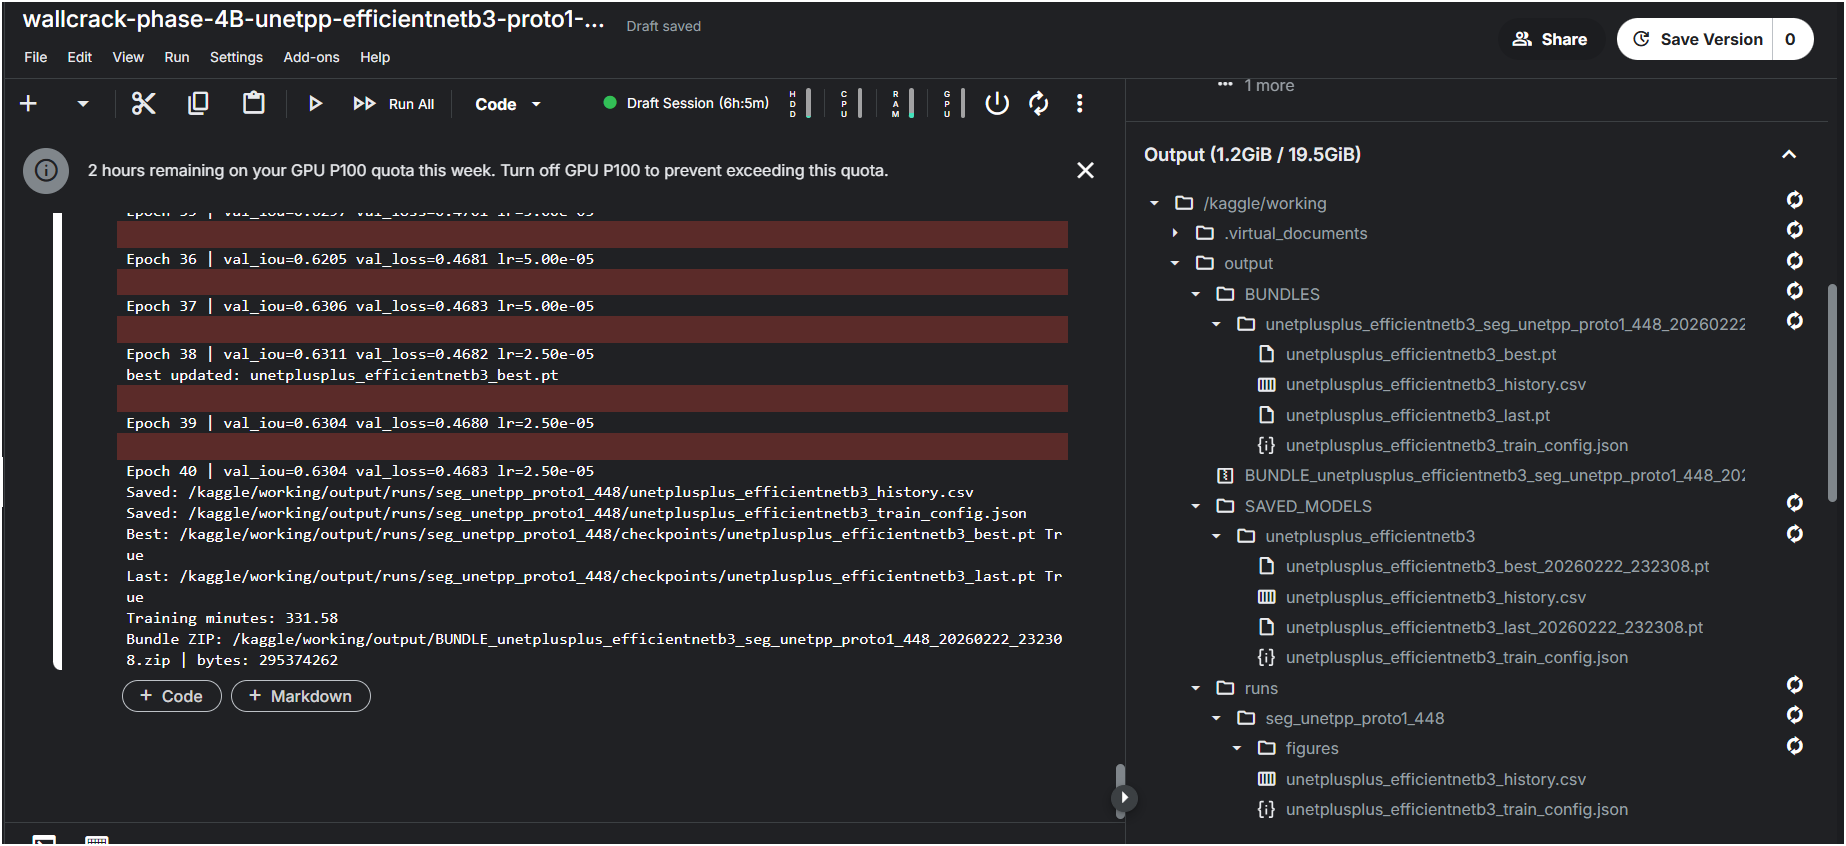

In [9]:
from pathlib import Path
import os, json


if "OUT" not in globals():
    OUT = Path("/kaggle/working/output")
if "MODEL_NAME" not in globals():
    MODEL_NAME = "unetplusplus_efficientnetb3"
if "RUN_NAME" not in globals():
    RUN_NAME = "seg_unetpp_proto1_448"

RUN_DIR = OUT / "runs" / RUN_NAME
FIG_DIR = RUN_DIR / "figures"
CKPT_DIR = RUN_DIR / "checkpoints"
BUNDLES_DIR = OUT / "BUNDLES"
SAVED_MODELS_DIR = OUT / "SAVED_MODELS" / MODEL_NAME

BEST_PATH = CKPT_DIR / f"{MODEL_NAME}_best.pt"
LAST_PATH = CKPT_DIR / f"{MODEL_NAME}_last.pt"

print("RUN_DIR:", RUN_DIR)
print("CKPT_DIR:", CKPT_DIR)
print("BEST_PATH:", BEST_PATH, "| exists:", BEST_PATH.exists())
print("LAST_PATH:", LAST_PATH, "| exists:", LAST_PATH.exists())

print("\nContents of RUN_DIR:")
if RUN_DIR.exists():
    for p in sorted(RUN_DIR.glob("**/*")):
        if p.is_file():
            print(" -", p.relative_to(RUN_DIR), "|", p.stat().st_size, "bytes")

print("\nContents of CKPT_DIR:")
!ls -lah "{CKPT_DIR}" || true

RUN_DIR: /kaggle/working/output/runs/seg_unetpp_proto1_448
CKPT_DIR: /kaggle/working/output/runs/seg_unetpp_proto1_448/checkpoints
BEST_PATH: /kaggle/working/output/runs/seg_unetpp_proto1_448/checkpoints/unetplusplus_efficientnetb3_best.pt | exists: True
LAST_PATH: /kaggle/working/output/runs/seg_unetpp_proto1_448/checkpoints/unetplusplus_efficientnetb3_last.pt | exists: True

Contents of RUN_DIR:
 - checkpoints/unetplusplus_efficientnetb3_best.pt | 159764533 bytes
 - checkpoints/unetplusplus_efficientnetb3_last.pt | 159764917 bytes
 - unetplusplus_efficientnetb3_history.csv | 5764 bytes
 - unetplusplus_efficientnetb3_train_config.json | 582 bytes

Contents of CKPT_DIR:
total 305M
drwxr-xr-x 2 root root 4.0K Feb 23 00:15 .
drwxr-xr-x 4 root root 4.0K Feb 23 05:38 ..
-rw-r--r-- 1 root root 153M Feb 23 05:13 unetplusplus_efficientnetb3_best.pt
-rw-r--r-- 1 root root 153M Feb 23 05:38 unetplusplus_efficientnetb3_last.pt


# Cell 10 — Load dependencies and recreate val augmentation

In [10]:
import numpy as np
import pandas as pd
import cv2
import torch

import albumentations as A
from albumentations.pytorch import ToTensorV2

from tqdm import tqdm


if "DEVICE" not in globals():
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_EVAL = (DEVICE.type == "cuda")


if "IMG_SIZE" not in globals():
    IMG_SIZE = 448


IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)


if "val_aug" not in globals():
    val_aug = A.Compose([
        A.Resize(IMG_SIZE, IMG_SIZE, interpolation=cv2.INTER_AREA),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(transpose_mask=True),
    ])

print("DEVICE:", DEVICE, "| AMP_EVAL:", AMP_EVAL)
print("val_aug OK")

DEVICE: cuda | AMP_EVAL: True
val_aug OK


# Cell 11 — Rebuild model (UNet++) and load BEST checkpoint

In [11]:
import segmentation_models_pytorch as smp

assert BEST_PATH.exists(), f"Missing BEST checkpoint: {BEST_PATH}"


model = smp.UnetPlusPlus(
    encoder_name="efficientnet-b3",
    encoder_weights=None, 
    in_channels=3,
    classes=1,
    activation=None
).to(DEVICE)

ckpt = torch.load(BEST_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print("Loaded BEST:", BEST_PATH)
print("Checkpoint epoch:", ckpt.get("epoch", None))

Loaded BEST: /kaggle/working/output/runs/seg_unetpp_proto1_448/checkpoints/unetplusplus_efficientnetb3_best.pt
Checkpoint epoch: 37


# Cell 12 — Curves (loss/IoU/acc) from history CSV, saved high DPI

In [12]:
import matplotlib.pyplot as plt

FIG_DIR.mkdir(parents=True, exist_ok=True)

hist_csv = RUN_DIR / f"{MODEL_NAME}_history.csv"
assert hist_csv.exists(), f"Missing history CSV: {hist_csv}"
hist_df = pd.read_csv(hist_csv)

def save_fig(path, dpi=500):
    plt.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    print("Saved:", path)

# Loss
plt.figure(figsize=(7.2, 4.6))
plt.plot(hist_df["epoch"], hist_df["train_loss"], label="train_loss")
plt.plot(hist_df["epoch"], hist_df["val_loss"], label="val_loss")
plt.title("Loss vs Epoch"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
save_fig(FIG_DIR / f"{MODEL_NAME}_loss_curve.png")
plt.close()

# IoU
plt.figure(figsize=(7.2, 4.6))
plt.plot(hist_df["epoch"], hist_df["train_iou"], label="train_iou")
plt.plot(hist_df["epoch"], hist_df["val_iou"], label="val_iou")
plt.title("IoU vs Epoch"); plt.xlabel("Epoch"); plt.ylabel("IoU"); plt.legend()
save_fig(FIG_DIR / f"{MODEL_NAME}_iou_curve.png")
plt.close()

# Pixel accuracy
plt.figure(figsize=(7.2, 4.6))
plt.plot(hist_df["epoch"], hist_df["train_acc"], label="train_acc")
plt.plot(hist_df["epoch"], hist_df["val_acc"], label="val_acc")
plt.title("Pixel Accuracy vs Epoch"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
save_fig(FIG_DIR / f"{MODEL_NAME}_pixel_acc_curve.png")
plt.close()

Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_loss_curve.png
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_iou_curve.png
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_pixel_acc_curve.png


# Cell 13 — Validation per-image metrics + summary report (empty-mask correct)

In [13]:
from torch.utils.data import Dataset, DataLoader

EVAL_THR = 0.50
MIN_COMPONENT_AREA = 30
eps = 1e-6


if "df_val" not in globals():

    KAGGLE_INPUT = Path("/kaggle/input")
    val_split_csv = sorted(KAGGLE_INPUT.rglob("val_split.csv"))[0]
    train_split_csv = sorted(KAGGLE_INPUT.rglob("train_split.csv"))[0]

    # find dataset root
    seg_root = sorted([p for p in KAGGLE_INPUT.rglob("crack_segmentation_dataset") if p.is_dir()])[0]
    images_dir = seg_root / "images"
    masks_dir = seg_root / "masks"

    def build_stem_index(folder: Path):
        return {p.stem: p for p in folder.glob("*") if p.is_file()}

    img_index = build_stem_index(images_dir)
    msk_index = build_stem_index(masks_dir)

    def resolve_paths(df: pd.DataFrame) -> pd.DataFrame:
        df = df.copy()
        if "stem" not in df.columns:
            if "image_path" in df.columns:
                df["stem"] = df["image_path"].apply(lambda x: Path(str(x)).stem)
            elif "image" in df.columns:
                df["stem"] = df["image"].apply(lambda x: Path(str(x)).stem)
            else:
                raise ValueError("Split CSV missing stem.")
        if "image_path" not in df.columns:
            df["image_path"] = np.nan
        if "mask_path" not in df.columns:
            df["mask_path"] = np.nan

        def _resolve_img(stem, ip):
            ip = Path(str(ip)) if pd.notna(ip) else None
            if ip is not None and str(ip).startswith("/kaggle") and ip.exists():
                return str(ip)
            return str(img_index[stem])

        def _resolve_msk(stem, mp):
            mp = Path(str(mp)) if pd.notna(mp) else None
            if mp is not None and str(mp).startswith("/kaggle") and mp.exists():
                return str(mp)
            return str(msk_index[stem])

        df["image_path"] = [_resolve_img(st, ip) for st, ip in zip(df["stem"], df["image_path"])]
        df["mask_path"]  = [_resolve_msk(st, mp) for st, mp in zip(df["stem"], df["mask_path"])]
        return df[["stem", "image_path", "mask_path"]]

    df_val = resolve_paths(pd.read_csv(val_split_csv))

def remove_small_components(mask01: np.ndarray, min_area: int = 30) -> np.ndarray:
    m = (mask01.astype(np.uint8) * 255)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    out = np.zeros_like(mask01, dtype=np.uint8)
    for k in range(1, n):
        area = stats[k, cv2.CC_STAT_AREA]
        if area >= min_area:
            out[labels == k] = 1
    return out

class ValDatasetWithPaths(Dataset):
    def __init__(self, df, aug):
        self.df = df.reset_index(drop=True)
        self.aug = aug
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        r = self.df.iloc[idx]
        ip, mp, stem = r["image_path"], r["mask_path"], r["stem"]

        img = cv2.imread(ip, cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        m = (m > 127).astype(np.uint8)

        out = self.aug(image=img, mask=m)
        x = out["image"]
        y = out["mask"]
        if y.ndim == 2:
            y = y.unsqueeze(0)
        return x, y.float(), stem, ip, mp

val_eval_ds = ValDatasetWithPaths(df_val, val_aug)
val_eval_loader = DataLoader(val_eval_ds, batch_size=12, shuffle=False, num_workers=0, pin_memory=True)

autocast_kwargs = dict(device_type=DEVICE.type, enabled=AMP_EVAL)
if AMP_EVAL:
    autocast_kwargs["dtype"] = torch.float16

rows = []
model.eval()
with torch.no_grad():
    for xb, yb, stems, ips, mps in tqdm(val_eval_loader, desc="Val metrics", leave=False):
        xb = xb.to(DEVICE, dtype=torch.float32, non_blocking=True)
        yb = yb.to(DEVICE, dtype=torch.float32, non_blocking=True)

        with torch.autocast(**autocast_kwargs):
            logits = model(xb)

        probs = torch.sigmoid(logits).float()
        pred = (probs > EVAL_THR).float()

        inter = (pred * yb).sum(dim=(1,2,3))
        union = (pred + yb - pred*yb).sum(dim=(1,2,3))
        iou = ((inter + eps) / (union + eps)).detach().cpu().numpy()

        dice = ((2*inter + eps) / (pred.sum(dim=(1,2,3)) + yb.sum(dim=(1,2,3)) + eps)).detach().cpu().numpy()

        gt_px = yb.sum(dim=(1,2,3)).detach().cpu().numpy()
        pr_px = pred.sum(dim=(1,2,3)).detach().cpu().numpy()

        probs_np = probs[:,0].detach().cpu().numpy()
        pred_np  = pred[:,0].detach().cpu().numpy().astype(np.uint8)

        # has_crack after removing tiny components (controls false positives)
        pred_has = []
        for b in range(pred_np.shape[0]):
            pm = remove_small_components(pred_np[b], min_area=MIN_COMPONENT_AREA)
            pred_has.append(int(pm.sum() > 0))
        pred_has = np.array(pred_has, dtype=int)

        gt_has = (gt_px > 0).astype(int)

        conf_p95 = np.percentile(probs_np.reshape(probs_np.shape[0], -1), 95, axis=1)
        conf_max = probs_np.reshape(probs_np.shape[0], -1).max(axis=1)

        conf_mean_pred = []
        for b in range(pred_np.shape[0]):
            m = pred_np[b].astype(bool)
            conf_mean_pred.append(float(probs_np[b][m].mean()) if m.any() else 0.0)

        for k in range(len(stems)):
            rows.append({
                "stem": str(stems[k]),
                "image_path": str(ips[k]),
                "mask_path": str(mps[k]),
                "iou": float(iou[k]),
                "dice": float(dice[k]),
                "gt_crack_pixels": int(gt_px[k]),
                "pred_crack_pixels": int(pr_px[k]),
                "gt_has_crack": int(gt_has[k]),
                "pred_has_crack": int(pred_has[k]),
                "conf_p95": float(conf_p95[k]),
                "conf_max": float(conf_max[k]),
                "conf_mean_pred": float(conf_mean_pred[k]),
            })

val_metrics_df = pd.DataFrame(rows)

# Empty-aware IoU (for completeness)
val_metrics_df["iou_emptyaware"] = val_metrics_df["iou"]
empty_gt = (val_metrics_df["gt_has_crack"] == 0)
empty_pr = (val_metrics_df["pred_has_crack"] == 0)
val_metrics_df.loc[empty_gt & empty_pr, "iou_emptyaware"] = 1.0
val_metrics_df.loc[empty_gt & (~empty_pr), "iou_emptyaware"] = 0.0

crack_df = val_metrics_df[val_metrics_df["gt_has_crack"] == 1]
noc_df   = val_metrics_df[val_metrics_df["gt_has_crack"] == 0]

summary = {
    "MODEL_NAME": MODEL_NAME,
    "RUN_NAME": RUN_NAME,
    "IMG_SIZE": int(IMG_SIZE),
    "EVAL_THR": float(EVAL_THR),
    "MIN_COMPONENT_AREA": int(MIN_COMPONENT_AREA),
    "n_val": int(len(val_metrics_df)),
    "n_gt_crack": int(len(crack_df)),
    "n_gt_nocrack": int(len(noc_df)),
    "mean_iou_all": float(val_metrics_df["iou"].mean()),
    "mean_iou_crack_only": float(crack_df["iou"].mean()) if len(crack_df) else float("nan"),
    "median_iou_crack_only": float(crack_df["iou"].median()) if len(crack_df) else float("nan"),
    "mean_dice_crack_only": float(crack_df["dice"].mean()) if len(crack_df) else float("nan"),
    "no_crack_false_positive_rate": float((noc_df["pred_has_crack"] == 1).mean()) if len(noc_df) else float("nan"),
    "no_crack_false_positive_count": int((noc_df["pred_has_crack"] == 1).sum()) if len(noc_df) else 0,
    "mean_iou_emptyaware_all": float(val_metrics_df["iou_emptyaware"].mean()),
}

val_metrics_path = RUN_DIR / f"{MODEL_NAME}_val_metrics.csv"
val_summary_path = RUN_DIR / f"{MODEL_NAME}_val_summary_report.csv"
val_metrics_df.to_csv(val_metrics_path, index=False)
pd.DataFrame([summary]).to_csv(val_summary_path, index=False)

print("Saved:", val_metrics_path)
print("Saved:", val_summary_path)
pd.DataFrame([summary]).T

Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/unetplusplus_efficientnetb3_val_metrics.csv
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/unetplusplus_efficientnetb3_val_summary_report.csv


,0
MODEL_NAME,unetplusplus_efficientnetb3
RUN_NAME,seg_unetpp_proto1_448
IMG_SIZE,448
EVAL_THR,0.5
MIN_COMPONENT_AREA,30
n_val,1695
n_gt_crack,1477
n_gt_nocrack,218
mean_iou_all,0.632402
mean_iou_crack_only,0.582208


# Cell 14 — Pixel PR curve + PR-AUC (sampled pixels, memory-safe)

In [14]:
try:
    from sklearn.metrics import precision_recall_curve, auc
except Exception:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-cache-dir", "-U", "scikit-learn"])
    from sklearn.metrics import precision_recall_curve, auc

import matplotlib.pyplot as plt

MAX_PR_PIXELS = 300_000
rng = np.random.default_rng(SEED if "SEED" in globals() else 7)

probs_all = []
gts_all = []
collected = 0

model.eval()
with torch.no_grad():
    for xb, yb, *_ in tqdm(val_eval_loader, desc="PR sampling", leave=False):
        if collected >= MAX_PR_PIXELS:
            break
        xb = xb.to(DEVICE, dtype=torch.float32, non_blocking=True)
        yb = yb.to(DEVICE, dtype=torch.float32, non_blocking=True)

        with torch.autocast(**autocast_kwargs):
            logits = model(xb)
        probs = torch.sigmoid(logits).float()

        p = probs[:,0].detach().cpu().numpy().reshape(-1)
        g = yb[:,0].detach().cpu().numpy().reshape(-1).astype(np.uint8)

        take = min(g.size, MAX_PR_PIXELS - collected)
        idx = rng.choice(g.size, size=take, replace=False)
        probs_all.append(p[idx])
        gts_all.append(g[idx])
        collected += take

probs_all = np.concatenate(probs_all)
gts_all = np.concatenate(gts_all)

prec, rec, _ = precision_recall_curve(gts_all, probs_all)
pr_auc = auc(rec, prec)

plt.figure(figsize=(6.8, 5.2))
plt.plot(rec, prec)
plt.title(f"Pixel Precision–Recall (AUC={pr_auc:.3f}, sampled={collected:,})")
plt.xlabel("Recall"); plt.ylabel("Precision")
pr_fig = FIG_DIR / f"{MODEL_NAME}_pixel_pr_curve.png"
plt.savefig(pr_fig, dpi=500, bbox_inches="tight", facecolor="white")
plt.close()
print("Saved:", pr_fig)

auc_path = RUN_DIR / f"{MODEL_NAME}_val_pr_auc_pixel.csv"
pd.DataFrame([{"MODEL_NAME": MODEL_NAME, "pixel_pr_auc": float(pr_auc), "sampled_pixels": int(collected)}]).to_csv(auc_path, index=False)
print("Saved:", auc_path)
print("Pixel PR AUC:", pr_auc)

Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_pixel_pr_curve.png
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/unetplusplus_efficientnetb3_val_pr_auc_pixel.csv
Pixel PR AUC: 0.890335433789265


# Cell 15 — Histograms (IoU all/crack-only, crack area, confidence)

In [15]:
import matplotlib.pyplot as plt

# IoU all
plt.figure(figsize=(7.2, 4.4))
plt.hist(val_metrics_df["iou"], bins=30)
plt.title("Validation IoU Distribution (All)")
plt.xlabel("IoU"); plt.ylabel("Count")
p = FIG_DIR / f"{MODEL_NAME}_val_iou_hist_all.png"
plt.savefig(p, dpi=500, bbox_inches="tight", facecolor="white")
plt.close()
print("Saved:", p)

# IoU crack-only
crack_df = val_metrics_df[val_metrics_df["gt_has_crack"] == 1]
plt.figure(figsize=(7.2, 4.4))
plt.hist(crack_df["iou"], bins=30)
plt.title("Validation IoU Distribution (Crack-present only)")
plt.xlabel("IoU"); plt.ylabel("Count")
p = FIG_DIR / f"{MODEL_NAME}_val_iou_hist_crack_only.png"
plt.savefig(p, dpi=500, bbox_inches="tight", facecolor="white")
plt.close()
print("Saved:", p)

# GT crack area
plt.figure(figsize=(7.2, 4.4))
plt.hist(crack_df["gt_crack_pixels"], bins=30)
plt.title("GT Crack Area Proxy (pixels) — Crack-present only")
plt.xlabel("GT crack pixels"); plt.ylabel("Count")
p = FIG_DIR / f"{MODEL_NAME}_gt_crack_area_hist.png"
plt.savefig(p, dpi=500, bbox_inches="tight", facecolor="white")
plt.close()
print("Saved:", p)

# Pred crack area (all)
plt.figure(figsize=(7.2, 4.4))
plt.hist(val_metrics_df["pred_crack_pixels"], bins=30)
plt.title("Predicted Crack Area Proxy (pixels) — All val")
plt.xlabel("Pred crack pixels"); plt.ylabel("Count")
p = FIG_DIR / f"{MODEL_NAME}_pred_crack_area_hist.png"
plt.savefig(p, dpi=500, bbox_inches="tight", facecolor="white")
plt.close()
print("Saved:", p)

# Confidence histograms
plt.figure(figsize=(7.2, 4.4))
plt.hist(val_metrics_df["conf_p95"], bins=30)
plt.title("Confidence (P95 pixel prob) — All val")
plt.xlabel("conf_p95"); plt.ylabel("Count")
p = FIG_DIR / f"{MODEL_NAME}_confidence_p95_hist.png"
plt.savefig(p, dpi=500, bbox_inches="tight", facecolor="white")
plt.close()
print("Saved:", p)

plt.figure(figsize=(7.2, 4.4))
plt.hist(val_metrics_df["conf_mean_pred"], bins=30)
plt.title("Confidence (mean prob inside predicted mask) — All val")
plt.xlabel("conf_mean_pred"); plt.ylabel("Count")
p = FIG_DIR / f"{MODEL_NAME}_confidence_mean_pred_hist.png"
plt.savefig(p, dpi=500, bbox_inches="tight", facecolor="white")
plt.close()
print("Saved:", p)

Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_val_iou_hist_all.png
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_val_iou_hist_crack_only.png
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_gt_crack_area_hist.png
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_pred_crack_area_hist.png
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_confidence_p95_hist.png
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_confidence_mean_pred_hist.png


# Cell 16 — Top-K worst gallery (crack-present only)

In [16]:
import matplotlib.pyplot as plt

K = 12
worst = (val_metrics_df[val_metrics_df["gt_has_crack"] == 1]
         .sort_values("iou", ascending=True)
         .head(K)
         .reset_index(drop=True))

def read_rgb(path, size):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return img

def read_mask01(path, size):
    m = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    m = (m > 127).astype(np.uint8)
    m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
    return m

def overlay_mask(img_rgb, mask01, alpha=0.35):
    out = img_rgb.astype(np.float32).copy()
    m = mask01.astype(bool)
    out[m] = (1-alpha)*out[m] + alpha*np.array([255,0,0], dtype=np.float32)
    return out.clip(0,255).astype(np.uint8)

fig, axes = plt.subplots(len(worst), 5, figsize=(16, 3.0 * len(worst)))
fig.suptitle("Top-K Worst (Crack-present only): Image | GT | Pred | Overlay | Prob heatmap", y=1.002)

model.eval()
with torch.no_grad():
    for r in range(len(worst)):
        ip = worst.loc[r, "image_path"]
        mp = worst.loc[r, "mask_path"]
        stem = worst.loc[r, "stem"]

        img = read_rgb(ip, IMG_SIZE)
        gt  = read_mask01(mp, IMG_SIZE)

        out = val_aug(image=img, mask=gt)
        x = out["image"].unsqueeze(0).to(DEVICE, dtype=torch.float32)

        with torch.autocast(**autocast_kwargs):
            logits = model(x)

        prob = torch.sigmoid(logits).squeeze().float().cpu().numpy()
        pred = (prob > EVAL_THR).astype(np.uint8)

        axes[r,0].imshow(img); axes[r,0].axis("off"); axes[r,0].set_title(f"{stem}", fontsize=10)
        axes[r,1].imshow(gt, cmap="gray"); axes[r,1].axis("off"); axes[r,1].set_title("GT", fontsize=10)
        axes[r,2].imshow(pred, cmap="gray"); axes[r,2].axis("off"); axes[r,2].set_title(f"Pred IoU={worst.loc[r,'iou']:.3f}", fontsize=10)
        axes[r,3].imshow(overlay_mask(img, pred)); axes[r,3].axis("off"); axes[r,3].set_title("Overlay", fontsize=10)
        axes[r,4].imshow(prob, cmap="magma"); axes[r,4].axis("off"); axes[r,4].set_title("Prob", fontsize=10)

out_path = FIG_DIR / f"{MODEL_NAME}_topk_worst_crack_only_gallery.png"
fig.savefig(out_path, dpi=500, bbox_inches="tight", facecolor="white")
plt.close(fig)
print("Saved:", out_path)

Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_topk_worst_crack_only_gallery.png


# Cell 17 — Mask → AABB + OBB detections, overlays, JSONL

In [17]:
import json
import matplotlib.pyplot as plt

def mask_to_aabbs(mask01, min_area=30):
    m = (mask01.astype(np.uint8) * 255)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    boxes = []
    for k in range(1, n):
        x, y, w, h, area = stats[k]
        if area < min_area:
            continue
        boxes.append({"x1": int(x), "y1": int(y), "x2": int(x+w), "y2": int(y+h), "area_px": int(area)})
    boxes.sort(key=lambda d: d["area_px"], reverse=True)
    return boxes

def mask_to_obbs(mask01, min_area=30):
    m = (mask01.astype(np.uint8) * 255)
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    obbs = []
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area < float(min_area):
            continue
        rect = cv2.minAreaRect(cnt)
        box = cv2.boxPoints(rect).astype(np.int32).tolist()
        obbs.append({"box": box, "area_px": int(area),
                     "rect": {"cx": rect[0][0], "cy": rect[0][1], "w": rect[1][0], "h": rect[1][1], "angle": rect[2]}})
    obbs.sort(key=lambda d: d["area_px"], reverse=True)
    return obbs

def draw_aabbs(img_rgb, boxes, color=(255,0,0), lw=2, topk=3):
    out = img_rgb.copy()
    for b in boxes[:topk]:
        cv2.rectangle(out, (b["x1"], b["y1"]), (b["x2"], b["y2"]), color, lw)
    return out

def draw_obbs(img_rgb, obbs, color=(255,0,0), lw=2, topk=3):
    out = img_rgb.copy()
    for o in obbs[:topk]:
        pts = np.array(o["box"], dtype=np.int32).reshape(-1,1,2)
        cv2.polylines(out, [pts], True, color, lw)
    return out

N_SHOW = 10
rng = np.random.default_rng(SEED if "SEED" in globals() else 7)
idxs = rng.choice(len(df_val), size=min(N_SHOW, len(df_val)), replace=False)

detections_path = RUN_DIR / f"{MODEL_NAME}_val_detections_from_masks.jsonl"
fig, axes = plt.subplots(len(idxs), 4, figsize=(16, 3.1*len(idxs)))
fig.suptitle("Mask→Detection outputs: Image | GT AABB+OBB | Pred AABB+OBB | Pred overlay", y=1.002)

with detections_path.open("w") as f, torch.no_grad():
    for r, idx in enumerate(idxs):
        row = df_val.iloc[int(idx)]
        ip, mp, stem = row["image_path"], row["mask_path"], row["stem"]

        img = read_rgb(ip, IMG_SIZE)
        gt = read_mask01(mp, IMG_SIZE)

        out = val_aug(image=img, mask=gt)
        x = out["image"].unsqueeze(0).to(DEVICE, dtype=torch.float32)

        with torch.autocast(**autocast_kwargs):
            logits = model(x)

        prob = torch.sigmoid(logits).squeeze().float().cpu().numpy()
        pred = (prob > EVAL_THR).astype(np.uint8)

        gt_det = remove_small_components(gt, min_area=MIN_COMPONENT_AREA)
        pr_det = remove_small_components(pred, min_area=MIN_COMPONENT_AREA)

        gt_aabb = mask_to_aabbs(gt_det, MIN_COMPONENT_AREA)
        pr_aabb = mask_to_aabbs(pr_det, MIN_COMPONENT_AREA)
        gt_obb  = mask_to_obbs(gt_det, MIN_COMPONENT_AREA)
        pr_obb  = mask_to_obbs(pr_det, MIN_COMPONENT_AREA)

        rec = {
            "stem": stem,
            "image_path": str(ip),
            "mask_path": str(mp),
            "thr": float(EVAL_THR),
            "min_component_area": int(MIN_COMPONENT_AREA),
            "pred_area_px": int(pr_det.sum()),
            "conf_p95": float(np.percentile(prob.reshape(-1), 95)),
            "aabb_pred": pr_aabb,
            "obb_pred": pr_obb,
            "aabb_gt": gt_aabb,
            "obb_gt": gt_obb,
        }
        f.write(json.dumps(rec) + "\n")

        gt_vis = draw_obbs(draw_aabbs(img, gt_aabb, color=(0,255,0)), gt_obb, color=(0,255,0))
        pr_vis = draw_obbs(draw_aabbs(img, pr_aabb, color=(255,0,0)), pr_obb, color=(255,0,0))
        ov_vis = overlay_mask(img, pr_det, alpha=0.35)

        axes[r,0].imshow(img); axes[r,0].axis("off"); axes[r,0].set_title(stem, fontsize=10)
        axes[r,1].imshow(gt_vis); axes[r,1].axis("off"); axes[r,1].set_title("GT", fontsize=10)
        axes[r,2].imshow(pr_vis); axes[r,2].axis("off"); axes[r,2].set_title("Pred", fontsize=10)
        axes[r,3].imshow(ov_vis); axes[r,3].axis("off"); axes[r,3].set_title("Overlay", fontsize=10)

over_path = FIG_DIR / f"{MODEL_NAME}_bbox_obb_overlays.png"
fig.savefig(over_path, dpi=500, bbox_inches="tight", facecolor="white")
plt.close(fig)

print("Saved:", detections_path)
print("Saved:", over_path)

Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/unetplusplus_efficientnetb3_val_detections_from_masks.jsonl
Saved: /kaggle/working/output/runs/seg_unetpp_proto1_448/figures/unetplusplus_efficientnetb3_bbox_obb_overlays.png


# Cell 18 — FULL bundle ZIP (checkpoints + CSVs + figures + JSONL + split CSVs)

In [18]:
import time, shutil, json
from pathlib import Path

stamp = time.strftime("%Y%m%d_%H%M%S")
full_dir = OUT / "BUNDLES" / f"{MODEL_NAME}_{RUN_NAME}_FULL_{stamp}"
full_dir.mkdir(parents=True, exist_ok=True)

# Copy checkpoints
for p in [BEST_PATH, LAST_PATH]:
    assert Path(p).exists(), f"Missing: {p}"
    shutil.copy2(p, full_dir / Path(p).name)

# Copy key run files
for p in [
    RUN_DIR / f"{MODEL_NAME}_history.csv",
    RUN_DIR / f"{MODEL_NAME}_train_config.json",
    RUN_DIR / f"{MODEL_NAME}_val_metrics.csv",
    RUN_DIR / f"{MODEL_NAME}_val_summary_report.csv",
    RUN_DIR / f"{MODEL_NAME}_val_pr_auc_pixel.csv",
    RUN_DIR / f"{MODEL_NAME}_val_detections_from_masks.jsonl",
]:
    if p.exists():
        shutil.copy2(p, full_dir / p.name)

# Copy split CSVs for reproducibility
for p in [Path("/kaggle/input").rglob("train_split.csv"), Path("/kaggle/input").rglob("val_split.csv")]:
    pass
train_split = sorted(Path("/kaggle/input").rglob("train_split.csv"))[0]
val_split   = sorted(Path("/kaggle/input").rglob("val_split.csv"))[0]
shutil.copy2(train_split, full_dir / "train_split.csv")
shutil.copy2(val_split, full_dir / "val_split.csv")

# Copy figures
(fig_dst := full_dir / "figures").mkdir(parents=True, exist_ok=True)
for p in FIG_DIR.glob("*.png"):
    shutil.copy2(p, fig_dst / p.name)

# Manifest
manifest = {"created_at": stamp, "model_name": MODEL_NAME, "run_name": RUN_NAME,
            "files": sorted([str(p.relative_to(full_dir)) for p in full_dir.glob("**/*") if p.is_file()])}
(full_dir / "manifest.json").write_text(json.dumps(manifest, indent=2))

# Zip
zip_base = OUT / f"BUNDLE_FULL_{MODEL_NAME}_{RUN_NAME}_{stamp}"
shutil.make_archive(str(zip_base), "zip", root_dir=str(full_dir))
zip_path = Path(str(zip_base) + ".zip")

print("FULL bundle folder:", full_dir)
print("FULL bundle ZIP:", zip_path, "| bytes:", zip_path.stat().st_size)

from IPython.display import FileLink
FileLink(str(zip_path))

FULL bundle folder: /kaggle/working/output/BUNDLES/unetplusplus_efficientnetb3_seg_unetpp_proto1_448_FULL_20260223_054228
FULL bundle ZIP: /kaggle/working/output/BUNDLE_FULL_unetplusplus_efficientnetb3_seg_unetpp_proto1_448_20260223_054228.zip | bytes: 326298475


/kaggle/working/output/BUNDLE_FULL_unetplusplus_efficientnetb3_seg_unetpp_proto1_448_20260223_054228.zip